<a href="https://colab.research.google.com/github/Arvind-kumar2006/Attention_base_image_captioning/blob/main/captioning_Image.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Attention-Based Image Captioning — Milestones 1 & 2

**ResNet-50 encoder:** ImageNet weights → classification head removed → image passed through → feature-map shape printed → visualization.



**COCO data pipeline:** Karpathy caption JSON → tokenization → vocabulary → train/val/test split → `DataLoader`.

**Attention module:** region features + LSTM hidden state -> scores -> softmax -> weights (sum = 1) -> context vector.

**LSTM decoder:** `<start>` -> embedding -> attention -> LSTM -> next word -> ... -> `<end>`.

**End-to-end demo:** image -> ResNet encoder -> attention -> LSTM decoder -> caption + per-word attention maps.

> Runtime tip: use **Runtime -> Change runtime type -> T4 GPU** before running Part 6 (training).

In [1]:
import os, json, random, itertools, collections, urllib.request, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.utils import make_grid

COCO_ROOT_OVERRIDE = None

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| work dir:", WORK.resolve())

device: cuda | work dir: /content


In [2]:
def has_jpgs(folder):
    try:
        with os.scandir(folder) as it:
            for e in it:
                return e.name.lower().endswith((".jpg", ".jpeg"))
    except FileNotFoundError:
        pass
    return False

def find_coco_root(bases=("/kaggle/input", "/content/data/coco", "data/coco"), max_depth=5):
    """Find the folder that contains train2014/ and/or val2014/ holding .jpg files."""
    for base in bases:
        if not os.path.isdir(base):
            continue
        base_depth = base.rstrip("/").count("/")
        for dirpath, dirnames, _ in os.walk(base):
            if dirpath.rstrip("/").count("/") - base_depth >= max_depth:
                dirnames[:] = []
                continue
            for name in ("val2014", "train2014"):
                if name in dirnames and has_jpgs(Path(dirpath) / name):
                    return Path(dirpath)
    return None

def show_dirs(base, max_depth=4):
    """Print the folder structure (directories only) to help debug paths."""
    base_depth = str(base).rstrip("/").count("/")
    for dirpath, dirnames, _ in os.walk(base):
        depth = dirpath.rstrip("/").count("/") - base_depth
        print("  " * depth + os.path.basename(dirpath.rstrip("/")) + "/")
        if depth >= max_depth:
            dirnames[:] = []

COCO_ROOT = Path(COCO_ROOT_OVERRIDE) if COCO_ROOT_OVERRIDE else find_coco_root()


kh_path = None
if COCO_ROOT is None:
    try:
        import kagglehub
        kh_path = kagglehub.dataset_download("jeffaudi/coco-2014-dataset-for-yolov3")
        print("kagglehub path:", kh_path)
        COCO_ROOT = find_coco_root(bases=(kh_path,), max_depth=8)
    except Exception as e:
        print("kagglehub download failed:", repr(e))

if COCO_ROOT is None:
    if kh_path:
        print("\nFolders found under the download (please share this if the path is still not detected):")
        show_dirs(kh_path)
    raise AssertionError(
        "COCO images not found - set COCO_ROOT_OVERRIDE to the folder that contains train2014/ and val2014/")
print("COCO root:", COCO_ROOT )
for name in ("train2014", "val2014"):
    print(f"  {name}: {'found' if (COCO_ROOT / name).is_dir() else 'MISSING'}")

100%|██████████| 25.0G/25.0G [04:40<00:00, 95.6MB/s]


Extracting files...
kagglehub path: /root/.cache/kagglehub/datasets/jeffaudi/coco-2014-dataset-for-yolov3/versions/4
COCO root: /root/.cache/kagglehub/datasets/jeffaudi/coco-2014-dataset-for-yolov3/versions/4/coco2014/images
  train2014: found
  val2014: found


---
## Part 1 — ResNet-50 encoder

Images are resized straight to 224×224 (no crop) so the 7×7 grid covers the **whole** image — this keeps attention overlays aligned with the picture later.

In [3]:
WEIGHTS = ResNet50_Weights.IMAGENET1K_V1

preprocess = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


class Encoder(nn.Module):
    """ResNet-50 without avgpool + fc  ->  (B, 49, 2048) region features."""

    def __init__(self, full=None):
        super().__init__()
        if full is None:
            full = resnet50(weights=WEIGHTS)
        self.backbone = nn.Sequential(*list(full.children())[:-2])   # drop avgpool + fc
        for p in self.backbone.parameters():                          # frozen for now
            p.requires_grad = False

    def forward(self, x):
        f = self.backbone(x)                    # (B, 2048, 7, 7)
        return f.flatten(2).transpose(1, 2)     # (B, 49, 2048)

In [5]:
from google.colab import files

uploaded = files.upload()

Saving dog_playing.jpeg to dog_playing.jpeg


image           : dog_playing.jpeg (198, 148)
input tensor    : (1, 3, 224, 224)


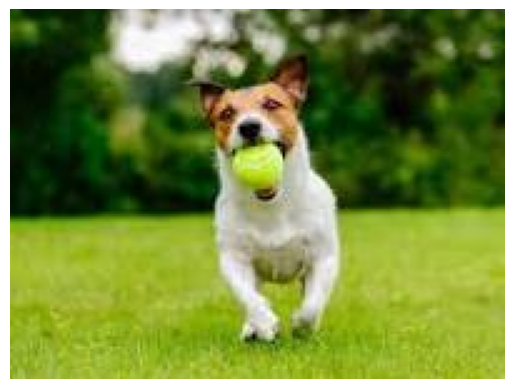

In [6]:
# Pick a sample image (or set SAMPLE_IMAGE to your own file path)
SAMPLE_IMAGE = "dog_playing.jpeg"

if SAMPLE_IMAGE is None:
    folder = COCO_ROOT / ("val2014" if (COCO_ROOT / "val2014").is_dir() else "train2014")
    with os.scandir(folder) as it:
        names = [e.name for e in itertools.islice(it, 300) if e.name.lower().endswith(".jpg")]
    SAMPLE_IMAGE = folder / random.choice(names)

img = Image.open(SAMPLE_IMAGE).convert("RGB")
x = preprocess(img).unsqueeze(0).to(device)
print("image           :", Path(SAMPLE_IMAGE).name, img.size)
print("input tensor    :", tuple(x.shape))
plt.imshow(img); plt.axis("off"); plt.show()

In [7]:
# 1) ResNet-50 with ImageNet weights - proof they loaded: it can classify the image
full = resnet50(weights=WEIGHTS).to(device).eval()
with torch.no_grad():
    top = full(x).softmax(1).topk(3)
cats = WEIGHTS.meta["categories"]
print("ImageNet top-3  :", [(cats[i], round(p.item(), 3)) for p, i in zip(top.values[0], top.indices[0])])

# 2) Classification head removed -> spatial feature map
print("head (unused)   :", full.fc)
enc = Encoder(full).to(device).eval()
with torch.no_grad():
    fmap = enc.backbone(x)      # (1, 2048, 7, 7)
    regions = enc(x)            # (1, 49, 2048)

print("feature map     :", tuple(fmap.shape), " -> (batch, channels, H, W)")
print("region features :", tuple(regions.shape), " -> 49 regions x 2048 dims")
print("trainable params:", sum(p.numel() for p in enc.parameters() if p.requires_grad), "(encoder frozen)")

# 3) Save features
torch.save(regions.cpu(), WORK / "features_demo.pt")
print("saved           :", WORK / "features_demo.pt")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 83.1MB/s]


ImageNet top-3  : [('wire-haired fox terrier', 0.541), ('tennis ball', 0.307), ('toy terrier', 0.074)]
head (unused)   : Linear(in_features=2048, out_features=1000, bias=True)
feature map     : (1, 2048, 7, 7)  -> (batch, channels, H, W)
region features : (1, 49, 2048)  -> 49 regions x 2048 dims
trainable params: 0 (encoder frozen)
saved           : features_demo.pt


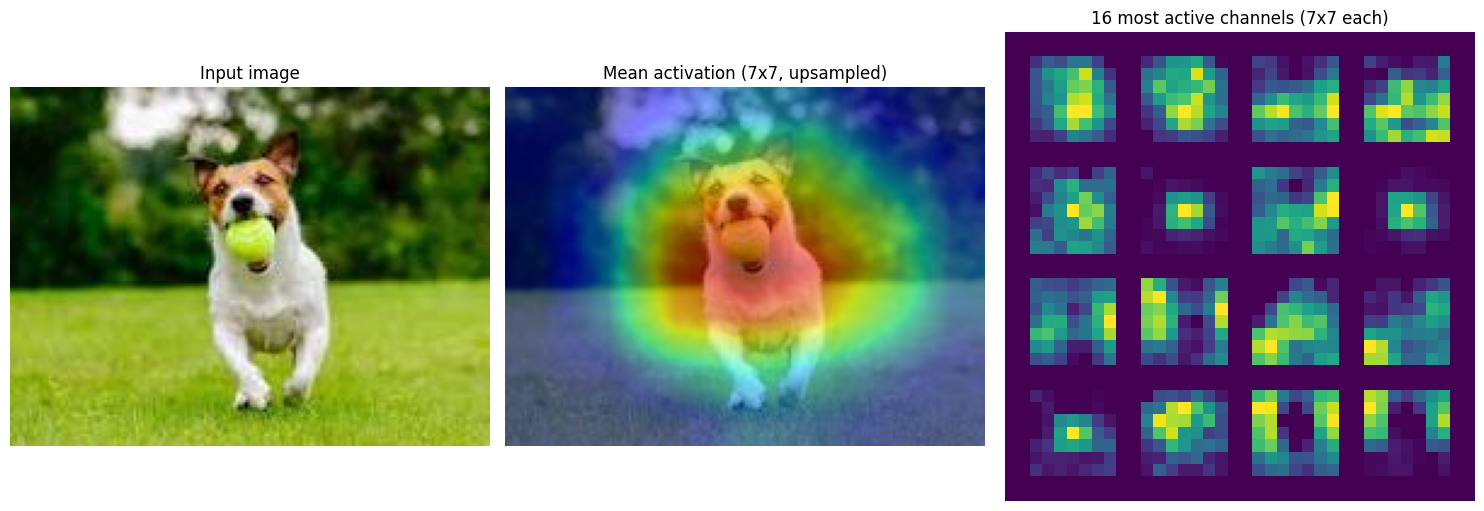

In [8]:
# 4) Visualize the features
fm = fmap[0].cpu()
heat = fm.mean(0)                                            # average over 2048 channels -> 7x7
heat = (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)
heat_up = F.interpolate(heat[None, None], size=img.size[::-1],
                        mode="bilinear", align_corners=False)[0, 0]
top16 = fm.mean((1, 2)).topk(16).indices                     # 16 most active channels
grid = make_grid(fm[top16].unsqueeze(1), nrow=4, normalize=True, scale_each=True)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img);                                  ax[0].set_title("Input image")
ax[1].imshow(img); ax[1].imshow(heat_up, alpha=0.5, cmap="jet")
ax[1].set_title("Mean activation (7x7, upsampled)")
ax[2].imshow(grid[0], cmap="viridis");              ax[2].set_title("16 most active channels (7x7 each)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(WORK / "encoder_features.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Part 2 — COCO caption data pipeline (Karpathy split)

`COCO image → caption JSON → tokenization → vocabulary → train / val / test split → DataLoader`

In [9]:
# Karpathy split file (dataset_coco.json) - downloaded once
KARPATHY = WORK / "dataset_coco.json"
if not KARPATHY.exists():
    url = "https://cs.stanford.edu/people/karpathy/deepimagesent/caption_datasets.zip"
    print("downloading Karpathy split (needs Internet ON) ...")
    zpath, _ = urllib.request.urlretrieve(url, str(WORK / "caption_datasets.zip"))
    with zipfile.ZipFile(zpath) as z:
        member = next(n for n in z.namelist() if n.endswith("dataset_coco.json"))
        with z.open(member) as src, open(KARPATHY, "wb") as dst:
            dst.write(src.read())
print("split file:", KARPATHY, f"({KARPATHY.stat().st_size / 1e6:.0f} MB)")

downloading Karpathy split (needs Internet ON) ...
split file: dataset_coco.json (144 MB)


In [10]:
PAD, START, END, UNK = 0, 1, 2, 3
MIN_FREQ, MAX_LEN = 5, 50          # keep words seen >= 5 times; drop train captions > 50 words


def build_splits(karpathy_json, coco_root, out_dir):
    images = json.load(open(karpathy_json))["images"]
    splits = {"train": [], "val": [], "test": []}
    counter, missing = collections.Counter(), 0

    for img in tqdm(images, desc="building splits"):
        if not (coco_root / img["filepath"] / img["filename"]).exists():
            missing += 1                                   # e.g. train2014 not downloaded
            continue
        split = "train" if img["split"] in ("train", "restval") else img["split"]   # Karpathy: restval -> train
        caps = [s["tokens"] for s in img["sentences"]]     # already lower-cased + tokenized
        if split == "train":
            caps = [c for c in caps if len(c) <= MAX_LEN]
            for c in caps:
                counter.update(c)
        if caps:
            splits[split].append({"path": f"{img['filepath']}/{img['filename']}", "caps": caps})

    vocab = {"<pad>": PAD, "<start>": START, "<end>": END, "<unk>": UNK}
    for w, c in sorted(counter.items()):
        if c >= MIN_FREQ:
            vocab[w] = len(vocab)

    for name, items in splits.items():
        with open(out_dir / f"{name}.json", "w") as f:
            json.dump(items, f)
    with open(out_dir / "vocab.json", "w") as f:
        json.dump(vocab, f)
    return splits, vocab, counter, missing


splits, vocab, counter, missing = build_splits(KARPATHY, COCO_ROOT, DATA)
inv_vocab = {i: w for w, i in vocab.items()}

print("entries skipped (image not on disk):", missing)
print()
for s, items in splits.items():
    n_caps = sum(len(i["caps"]) for i in items)
    print(f"{s:5s}: {len(items):>8,} images | {n_caps:>9,} captions")
print(f"\nvocabulary size : {len(vocab):,}")
print("10 most frequent:", counter.most_common(10))

TRAIN_SPLIT = "train" if splits["train"] else "val"
if TRAIN_SPLIT != "train":
    print("\nWARNING: no training images found - using 'val' as the train split for this demo.")

building splits:   0%|          | 0/123287 [00:00<?, ?it/s]

entries skipped (image not on disk): 46

train:  113,255 images |   566,587 captions
val  :    4,991 images |    24,965 captions
test :    4,995 images |    24,985 captions

vocabulary size : 9,993
10 most frequent: [('a', 936712), ('on', 206480), ('of', 195135), ('the', 189377), ('in', 176254), ('with', 147986), ('and', 134868), ('is', 94117), ('man', 70069), ('to', 65330)]


In [11]:
NORM = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

def get_transform(train):
    if train:
        return T.Compose([T.Resize(256), T.RandomCrop(224), T.ToTensor(), NORM])
    return T.Compose([T.Resize((224, 224)), T.ToTensor(), NORM])


class CocoCaptions(Dataset):
    """One item = (image tensor, caption ids). Train picks a random one of the 5 captions."""

    def __init__(self, items, vocab, root, train):
        self.items, self.vocab, self.root, self.train = items, vocab, Path(root), train
        self.tf = get_transform(train)

    def encode(self, tokens):
        return [START] + [self.vocab.get(w, UNK) for w in tokens] + [END]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        it = self.items[i]
        image = self.tf(Image.open(self.root / it["path"]).convert("RGB"))
        cap = random.choice(it["caps"]) if self.train else it["caps"][0]
        return image, torch.tensor(self.encode(cap))


def collate(batch):
    imgs, caps = zip(*batch)
    lengths = torch.tensor([len(c) for c in caps])
    return torch.stack(imgs), pad_sequence(caps, batch_first=True, padding_value=PAD), lengths


train_ds = CocoCaptions(splits[TRAIN_SPLIT], vocab, COCO_ROOT, train=True)
val_ds = CocoCaptions(splits["val"], vocab, COCO_ROOT, train=False)
print("train dataset:", len(train_ds), "| val dataset:", len(val_ds))

train dataset: 113255 | val dataset: 4991


image: val2014/COCO_val2014_000000085911.jpg 

  caption: a kite sitting in the middle of a large body of water
  caption: the kite has sank halfway down into the water
  caption: something sticking out of the body of water
  caption: kite with a persons face designed on it is floating in the water
  caption: a kite has fallen from the air in to the water

tokens : ['a', 'kite', 'sitting', 'in', 'the', 'middle', 'of', 'a', 'large', 'body', 'of', 'water']
ids    : [1, 67, 4718, 7852, 4412, 8893, 5403, 5858, 67, 4834, 991, 5858, 9658, 2]
decoded: <start> a kite sitting in the middle of a large body of water <end>


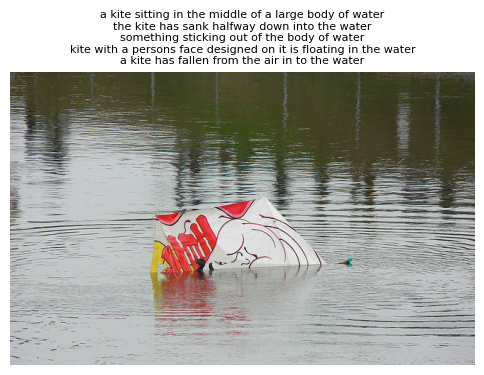

In [12]:
# Example: image + its captions + tokenization
item = random.choice(splits[TRAIN_SPLIT])
print("image:", item["path"], "\n")
for c in item["caps"]:
    print("  caption:", " ".join(c))

tokens = item["caps"][0]
ids = train_ds.encode(tokens)
print("\ntokens :", tokens)
print("ids    :", ids)
print("decoded:", " ".join(inv_vocab[i] for i in ids))

plt.figure(figsize=(6, 6))
plt.imshow(Image.open(COCO_ROOT / item["path"]).convert("RGB"))
plt.axis("off")
plt.title("\n".join(" ".join(c) for c in item["caps"][:5]), fontsize=8)
plt.savefig(WORK / "coco_example.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# DataLoader works
loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2, collate_fn=collate)
imgs, caps, lengths = next(iter(loader))
print("images           :", tuple(imgs.shape), " -> (batch, 3, 224, 224)")
print("captions (padded):", tuple(caps.shape), " -> (batch, max_len)")
print("lengths          :", lengths.tolist())
print("first caption ids:", caps[0].tolist())

val_imgs, val_caps, _ = next(iter(DataLoader(val_ds, batch_size=4, collate_fn=collate)))
print("val batch        :", tuple(val_imgs.shape), tuple(val_caps.shape))

images           : (8, 3, 224, 224)  -> (batch, 3, 224, 224)
captions (padded): (8, 16)  -> (batch, max_len)
lengths          : [12, 15, 10, 13, 15, 16, 13, 10]
first caption ids: [1, 67, 1337, 9846, 8893, 5794, 43, 8181, 5970, 9846, 1385, 2, 0, 0, 0, 0]
val batch        : (4, 3, 224, 224) (4, 13)


---
## Part 3 — Attention module

At every decoding step the decoder asks: *"which of the 49 image regions should I look at to produce the next word?"*

```
region features (49 x 2048)  +  LSTM hidden state (512)
            |
   attention scores  e_i = w^T tanh(W_f f_i + W_h h)      (one score per region)
            |
   softmax over the 49 regions
            |
   attention weights alpha   (sum = 1)
            |
   context vector = sum_i alpha_i * f_i                    (2048)
```

`W_f f_i + W_h h` is the same thing as one linear layer applied to `[f_i ; h]` (the PRD version) — it is just computed more cheaply.

In [14]:
class Attention(nn.Module):
    """Soft (deterministic) attention from Xu et al. 2015."""

    def __init__(self, feat_dim=2048, hidden_dim=512, attn_dim=512):
        super().__init__()
        self.feat_proj   = nn.Linear(feat_dim, attn_dim)     # W_f
        self.hidden_proj = nn.Linear(hidden_dim, attn_dim)   # W_h
        self.score       = nn.Linear(attn_dim, 1)            # w

    def forward(self, feats, h):
        """feats: (B, 49, 2048)   h: (B, hidden_dim)  ->  context (B, 2048), alpha (B, 49)"""
        e = self.score(torch.tanh(self.feat_proj(feats) + self.hidden_proj(h).unsqueeze(1))).squeeze(2)  # (B, 49)
        alpha = F.softmax(e, dim=1)                                  # weights over regions, sum to 1
        context = (feats * alpha.unsqueeze(2)).sum(dim=1)            # (B, 2048)
        return context, alpha

region features  : (1, 49, 2048)
hidden state     : (1, 512)
attention weights: (1, 49)  (one weight per region)
context vector   : (1, 2048)

Attention weights: [0.019, 0.017, 0.017, 0.016, 0.017, 0.02, 0.021, 0.018] ...
Sum = 1.000000
OK  sum ~= 1.0 (TEST-02 from the PRD)
Uniform would be 1/49 = 0.0204 -> untrained weights are near-uniform; they become peaked after training.


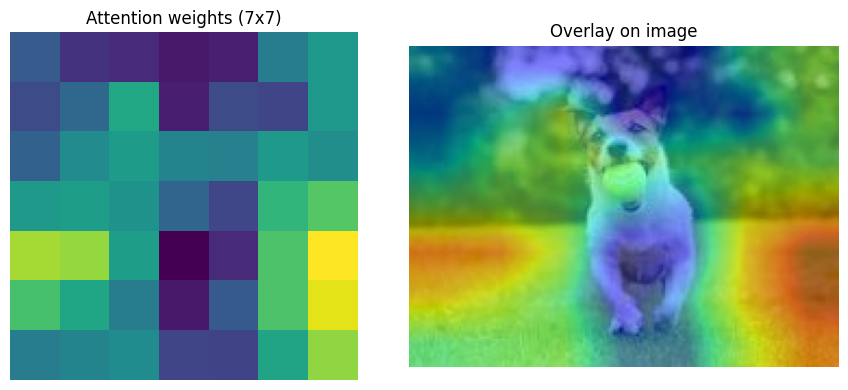

In [15]:
# --- Demo: attention weights sum to 1 (uses the `regions` tensor from Part 1) ---
torch.manual_seed(0)
attn = Attention().to(device).eval()
h_demo = torch.randn(1, 512, device=device)          # a fake LSTM hidden state

with torch.no_grad():
    ctx, alpha = attn(regions, h_demo)

print("region features  :", tuple(regions.shape))
print("hidden state     :", tuple(h_demo.shape))
print("attention weights:", tuple(alpha.shape), " (one weight per region)")
print("context vector   :", tuple(ctx.shape))
print()
print("Attention weights:", [round(v, 3) for v in alpha[0, :8].tolist()], "...")
print(f"Sum = {alpha.sum().item():.6f}")
assert abs(alpha.sum().item() - 1.0) < 1e-4, "attention weights must sum to ~1"
print("OK  sum ~= 1.0 (TEST-02 from the PRD)")
print("Uniform would be 1/49 =", round(1 / 49, 4), "-> untrained weights are near-uniform; they become peaked after training.")

a = alpha[0].cpu().view(7, 7)
a_up = F.interpolate(a[None, None], size=img.size[::-1], mode="bilinear", align_corners=False)[0, 0]
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(a, cmap="viridis"); ax[0].set_title("Attention weights (7x7)")
ax[1].imshow(img); ax[1].imshow(a_up, alpha=0.5, cmap="jet"); ax[1].set_title("Overlay on image")
for x_ in ax: x_.axis("off")
plt.tight_layout(); plt.show()

---
## Part 4 — LSTM decoder with attention

```
<start> -> Embedding -> [ Attention -> LSTM ] -> Linear -> next word
                              ^                                 |
                              +---------------------------------+   (repeat until <end>)
```

* **Training** uses *teacher forcing*: the ground-truth previous word is fed in at every step.
* **Inference** (`generate`) feeds back the model's own prediction (greedy decoding).
* A learned **gate** (`f_beta`) scales the context vector, as in the original paper.
* Loss = cross-entropy + *doubly stochastic attention regularisation* (encourages every region to be looked at at some point).

In [16]:
class DecoderWithAttention(nn.Module):
    def __init__(self, vocab_size, embed_dim=512, hidden_dim=512, feat_dim=2048, attn_dim=512, dropout=0.5):
        super().__init__()
        self.vocab_size, self.hidden_dim = vocab_size, hidden_dim
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        self.attention = Attention(feat_dim, hidden_dim, attn_dim)
        self.init_h    = nn.Linear(feat_dim, hidden_dim)          # initial state from mean image feature
        self.init_c    = nn.Linear(feat_dim, hidden_dim)
        self.f_beta    = nn.Linear(hidden_dim, feat_dim)          # gate on the context vector
        self.lstm      = nn.LSTMCell(embed_dim + feat_dim, hidden_dim)
        self.dropout   = nn.Dropout(dropout)
        self.fc        = nn.Linear(hidden_dim, vocab_size)

    def init_state(self, feats):
        mean = feats.mean(dim=1)                                  # (B, 2048)
        return torch.tanh(self.init_h(mean)), torch.tanh(self.init_c(mean))

    def step(self, word_ids, feats, h, c):
        """One decoding step. word_ids: (B,) -> logits (B, V), new h, c, alpha (B, 49)."""
        emb = self.embedding(word_ids)                            # (B, E)
        context, alpha = self.attention(feats, h)                 # look at the image
        context = torch.sigmoid(self.f_beta(h)) * context         # gate
        h, c = self.lstm(torch.cat([emb, context], dim=1), (h, c))
        logits = self.fc(self.dropout(h))
        return logits, h, c, alpha

    def forward(self, feats, caps):
        """Teacher forcing. caps: (B, T) incl. <start>/<end>/<pad>.
        Returns predictions (B, T-1, V) and alphas (B, T-1, 49) for targets caps[:, 1:]."""
        B, T = caps.shape
        h, c = self.init_state(feats)
        preds  = feats.new_zeros(B, T - 1, self.vocab_size)
        alphas = feats.new_zeros(B, T - 1, feats.size(1))
        for t in range(T - 1):
            logits, h, c, alpha = self.step(caps[:, t], feats, h, c)
            preds[:, t], alphas[:, t] = logits, alpha
        return preds, alphas

    @torch.no_grad()
    def generate(self, feats, max_len=20):
        """Greedy decoding. Returns word ids (B, <=max_len) and alphas (B, <=max_len, 49)."""
        B = feats.size(0)
        h, c = self.init_state(feats)
        word = torch.full((B,), START, dtype=torch.long, device=feats.device)
        ids, alphas = [], []
        for _ in range(max_len):
            logits, h, c, alpha = self.step(word, feats, h, c)
            word = logits.argmax(dim=1)
            ids.append(word); alphas.append(alpha)
            if (word == END).all():
                break
        return torch.stack(ids, dim=1), torch.stack(alphas, dim=1)


def caption_loss(preds, alphas, caps, alpha_c=1.0):
    """Cross-entropy (ignoring <pad>) + doubly stochastic attention regularisation."""
    targets = caps[:, 1:]
    ce = F.cross_entropy(preds.reshape(-1, preds.size(-1)), targets.reshape(-1), ignore_index=PAD)
    mask = (targets != PAD).float().unsqueeze(2)                  # only real words count
    alpha_sum = (alphas * mask).sum(dim=1)                        # (B, 49) total attention per region
    reg = ((1.0 - alpha_sum) ** 2).mean()
    return ce + alpha_c * reg, ce

In [17]:
# --- Sanity check on a real batch (untrained model) ---
import math
V = len(vocab)
decoder = DecoderWithAttention(V).to(device)
print("decoder params:", f"{sum(p.numel() for p in decoder.parameters()):,}")

imgs, caps, lengths = next(iter(loader))                          # batch from Part 2
imgs, caps = imgs.to(device), caps.to(device)
with torch.no_grad():
    feats = enc(imgs)                                             # (B, 49, 2048)
decoder.train()
preds, alphas = decoder(feats, caps)
loss, ce = caption_loss(preds, alphas, caps)

print("features    :", tuple(feats.shape))
print("captions    :", tuple(caps.shape))
print("predictions :", tuple(preds.shape), " -> (batch, steps, vocab)")
print("alphas      :", tuple(alphas.shape), " -> (batch, steps, 49 regions)")
print(f"initial CE loss = {ce.item():.2f}   (random guessing = ln(V) = {math.log(V):.2f})")
print("every step's attention sums to 1:", torch.allclose(alphas.sum(-1), torch.ones_like(alphas.sum(-1)), atol=1e-4))

decoder params: 20,999,434
features    : (8, 49, 2048)
captions    : (8, 18)
predictions : (8, 17, 9993)  -> (batch, steps, vocab)
alphas      : (8, 17, 49)  -> (batch, steps, 49 regions)
initial CE loss = 9.22   (random guessing = ln(V) = 9.21)
every step's attention sums to 1: True


In [18]:
# --- Proof the architecture can learn: overfit ONE batch (should drop far below ln(V)) ---
toy = DecoderWithAttention(V).to(device)
opt = torch.optim.Adam(toy.parameters(), lr=1e-3)
toy.train()
for step in range(1, 151):
    preds, alphas = toy(feats, caps)
    loss, ce = caption_loss(preds, alphas, caps)
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 30 == 0 or step == 1:
        print(f"step {step:3d} | CE {ce.item():.3f} | total {loss.item():.3f}")

toy.eval()
ids, _ = toy.generate(feats[:1], max_len=20)
gen = []
for i in ids[0].tolist():
    if i == END: break
    gen.append(inv_vocab[i])
truth = [inv_vocab[i] for i in caps[0].tolist() if i not in (PAD, START, END)]
print("\ngenerated:", " ".join(gen))
print("truth    :", " ".join(truth))
del toy, opt

step   1 | CE 9.193 | total 9.779
step  30 | CE 0.607 | total 1.198
step  60 | CE 0.082 | total 0.667
step  90 | CE 0.035 | total 0.619
step 120 | CE 0.019 | total 0.604
step 150 | CE 0.016 | total 0.600

generated: a woman holding a tennis racquet on top of a tennis court
truth    : a woman holding a tennis racquet on top of a tennis court


---
## Part 5 — End-to-end demo

`Input image -> ResNet encoder -> attention -> LSTM decoder -> generated caption` (+ the attention map behind every word).

At this point the decoder is **untrained**, so the caption is nonsense — that is expected. The point is that the whole pipeline runs. Part 6 trains it, and Part 7 re-runs this same demo.

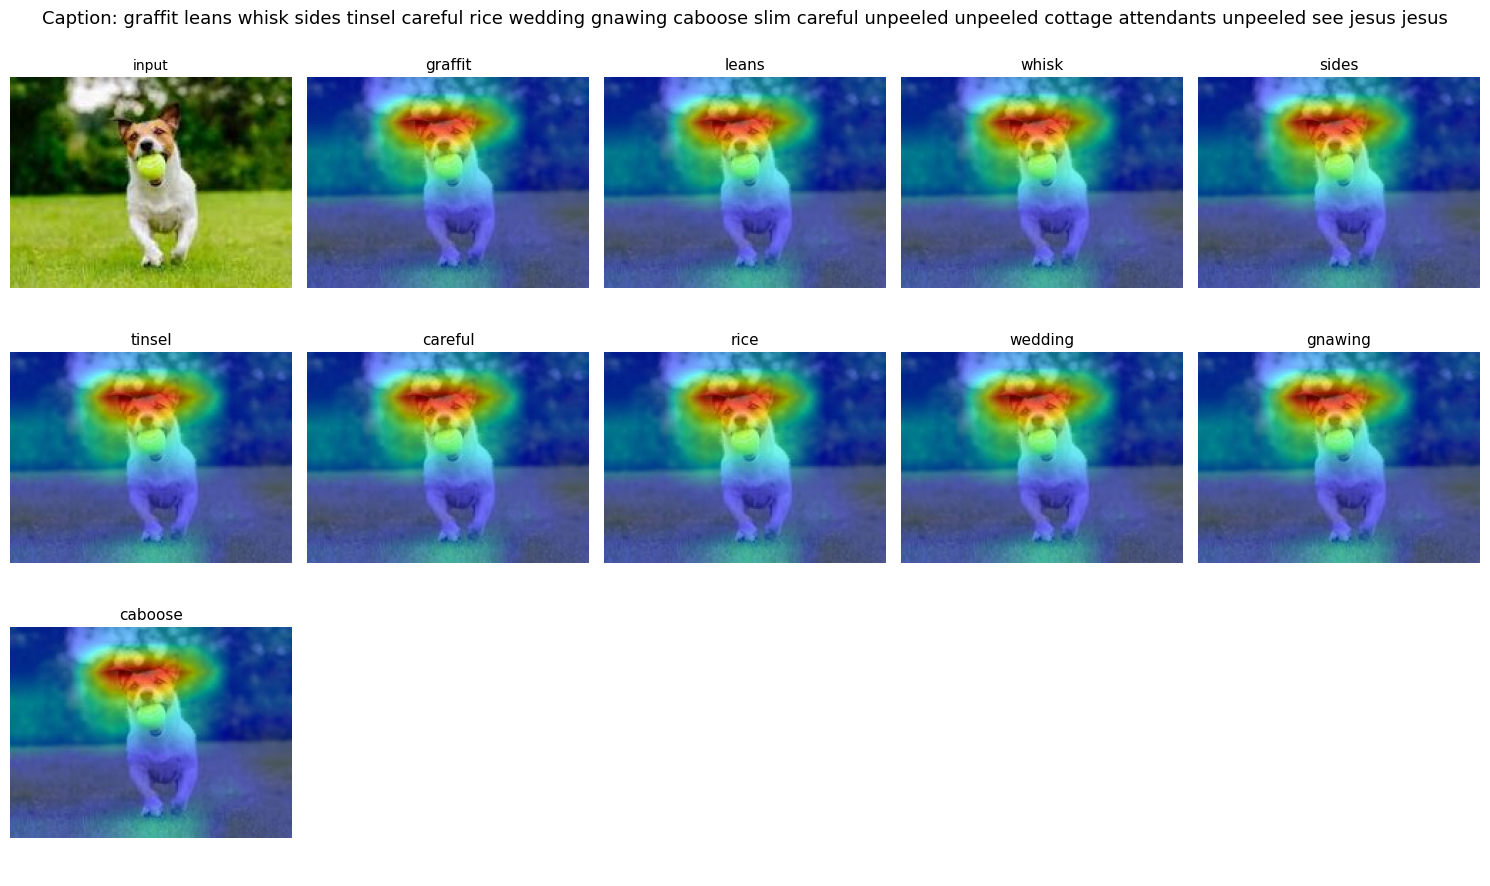

caption : graffit leans whisk sides tinsel careful rice wedding gnawing caboose slim careful unpeeled unpeeled cottage attendants unpeeled see jesus jesus
(untrained -> nonsense is expected; training is next)


In [19]:
def ids_to_words(ids):
    words = []
    for i in ids:
        if i == END:
            break
        words.append(inv_vocab.get(i, "<unk>"))
    return words


@torch.no_grad()
def caption_image(path, decoder, max_len=20, show=True, max_panels=10):
    """image path -> (caption string, words, per-word attention (n_words, 49))"""
    image = Image.open(path).convert("RGB")
    x_ = preprocess(image).unsqueeze(0).to(device)
    enc.eval(); decoder.eval()
    feats_ = enc(x_)                                              # (1, 49, 2048)
    ids, alphas_ = decoder.generate(feats_, max_len=max_len)
    words = ids_to_words(ids[0].tolist())
    att = alphas_[0, :len(words)].cpu()                           # (n_words, 49)
    caption = " ".join(words)

    if show:
        n = min(len(words), max_panels)
        cols = 5
        rows = max(1, math.ceil((n + 1) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows), squeeze=False)
        for a_ in axes.flat:
            a_.axis("off")
        axes[0, 0].imshow(image); axes[0, 0].set_title("input", fontsize=10)
        for k in range(n):
            a_ = axes.flat[k + 1]
            heat = F.interpolate(att[k].view(1, 1, 7, 7), size=image.size[::-1], mode="bilinear", align_corners=False)[0, 0]
            a_.imshow(image); a_.imshow(heat, alpha=0.55, cmap="jet")
            a_.set_title(words[k], fontsize=11)
        fig.suptitle(f"Caption: {caption}", fontsize=13)
        plt.tight_layout(); plt.show()
    return caption, words, att


caption, words, att = caption_image(SAMPLE_IMAGE, decoder)      # `decoder` = untrained one from Part 4
print("caption :", caption)
print("(untrained -> nonsense is expected; training is next)")

---
## Part 6 — Train the captioner (run on a **T4 GPU**)

The ResNet encoder stays frozen; only the decoder + attention are trained. Start with a subset so you see real captions in ~20-30 minutes, then set `TRAIN_SUBSET = None` for the full Karpathy train split.

| setting | quick demo | full run |
|---|---|---|
| `TRAIN_SUBSET` | 20000 | `None` (113k images) |
| `EPOCHS` | 5 | 10+ |

In [20]:
TRAIN_SUBSET = 20000          # None = full train split
EPOCHS       = 5
BATCH        = 64
LR           = 4e-4
ALPHA_C      = 1.0
CKPT         = WORK / "captioning_resnet_lstm_attn.pt"

if device == "cpu":
    print("WARNING: running on CPU - switch to a GPU runtime, training will be far too slow otherwise.")

items = splits[TRAIN_SPLIT]
if TRAIN_SUBSET:
    items = random.Random(0).sample(items, min(TRAIN_SUBSET, len(items)))
tr_ds = CocoCaptions(items, vocab, COCO_ROOT, train=True)
NW = min(4, os.cpu_count() or 2)
tr_loader = DataLoader(tr_ds, batch_size=BATCH, shuffle=True, num_workers=NW,
                       collate_fn=collate, pin_memory=(device == "cuda"), drop_last=True)
va_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=NW,
                       collate_fn=collate, pin_memory=(device == "cuda"))
print(f"train images: {len(tr_ds):,} | batches/epoch: {len(tr_loader)} | workers: {NW}")

train images: 20,000 | batches/epoch: 312 | workers: 2


  0%|          | 0/312 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

epoch 1/5 | train CE 4.725 | val CE 3.827
  saved -> captioning_resnet_lstm_attn.pt


  0%|          | 0/312 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

...

  0%|          | 0/78 [00:00<?, ?it/s]

epoch 4/5 | train CE 3.332 | val CE 3.036
  saved -> captioning_resnet_lstm_attn.pt


  0%|          | 0/312 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

epoch 5/5 | train CE 3.222 | val CE 2.942
  saved -> captioning_resnet_lstm_attn.pt


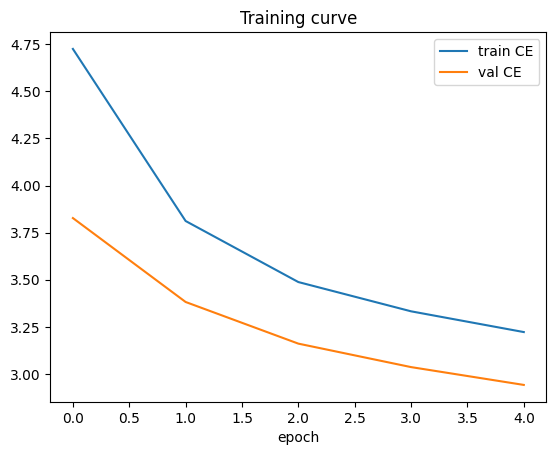

In [21]:
decoder = DecoderWithAttention(len(vocab)).to(device)             # fresh model
opt = torch.optim.Adam(decoder.parameters(), lr=LR)
use_amp = (device == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
enc.eval()                                                        # keep BatchNorm frozen

def run_epoch(loader, train, max_batches=None):
    decoder.train(train)
    tot, n = 0.0, 0
    for b, (im, cp, _) in enumerate(tqdm(loader, leave=False)):
        if max_batches and b >= max_batches:
            break
        im, cp = im.to(device, non_blocking=True), cp.to(device, non_blocking=True)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                with torch.no_grad():
                    f = enc(im)
                pr, al = decoder(f, cp)
            loss, ce = caption_loss(pr.float(), al.float(), cp, ALPHA_C)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(decoder.parameters(), 5.0)
                scaler.step(opt); scaler.update()
        tot += ce.item(); n += 1
    return tot / max(n, 1)

best, history = float("inf"), []
for ep in range(1, EPOCHS + 1):
    tr = run_epoch(tr_loader, True)
    va = run_epoch(va_loader, False, max_batches=40)
    history.append((tr, va))
    print(f"epoch {ep}/{EPOCHS} | train CE {tr:.3f} | val CE {va:.3f}")
    if va < best:
        best = va
        torch.save({"decoder": decoder.state_dict(), "vocab": vocab,
                    "cfg": {"embed_dim": 512, "hidden_dim": 512, "feat_dim": 2048, "attn_dim": 512}}, CKPT)
        print("  saved ->", CKPT)

plt.plot([h[0] for h in history], label="train CE"); plt.plot([h[1] for h in history], label="val CE")
plt.xlabel("epoch"); plt.legend(); plt.title("Training curve"); plt.show()

---
## Part 7 — Demo again with the trained model

Same pipeline as Part 5, now with trained weights. The attention maps should highlight the object for content words (dog, grass, ball...).

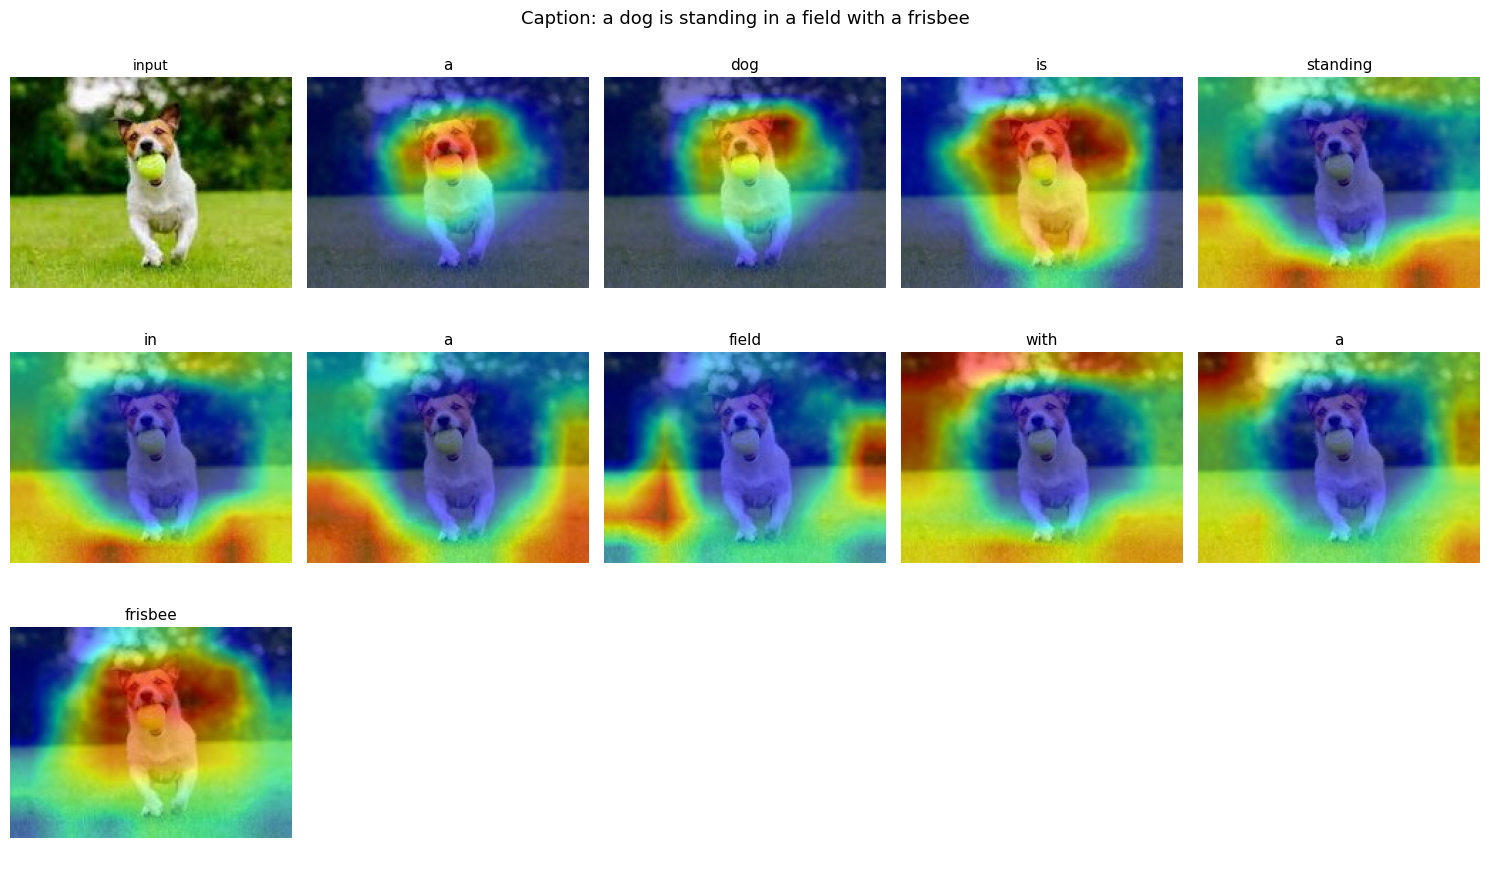

Your image -> a dog is standing in a field with a frisbee


In [22]:
ck = torch.load(CKPT, map_location=device)
decoder = DecoderWithAttention(len(ck["vocab"]), **ck["cfg"]).to(device)
decoder.load_state_dict(ck["decoder"]); decoder.eval()

caption, words, att = caption_image(SAMPLE_IMAGE, decoder)
print("Your image ->", caption)

reference : a boy does a jump with a skateboard while a girl watches


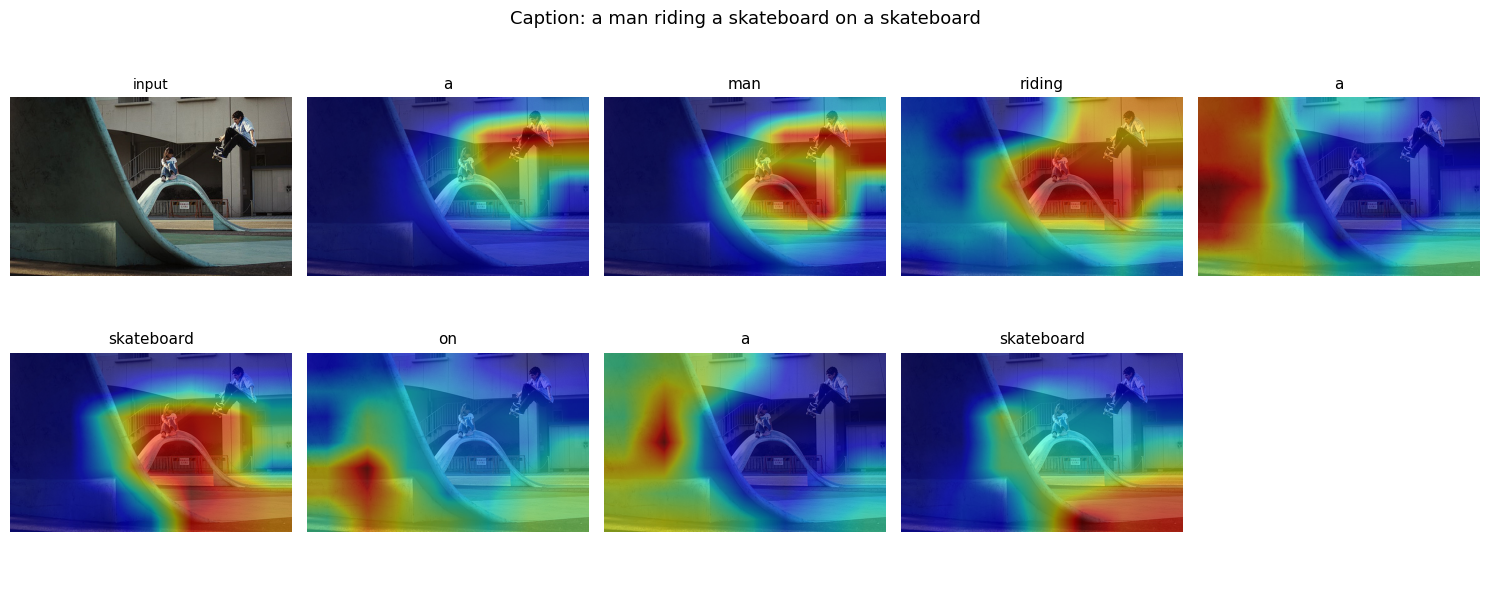

generated : a man riding a skateboard on a skateboard 

reference : a number of people sitting at tables in a train


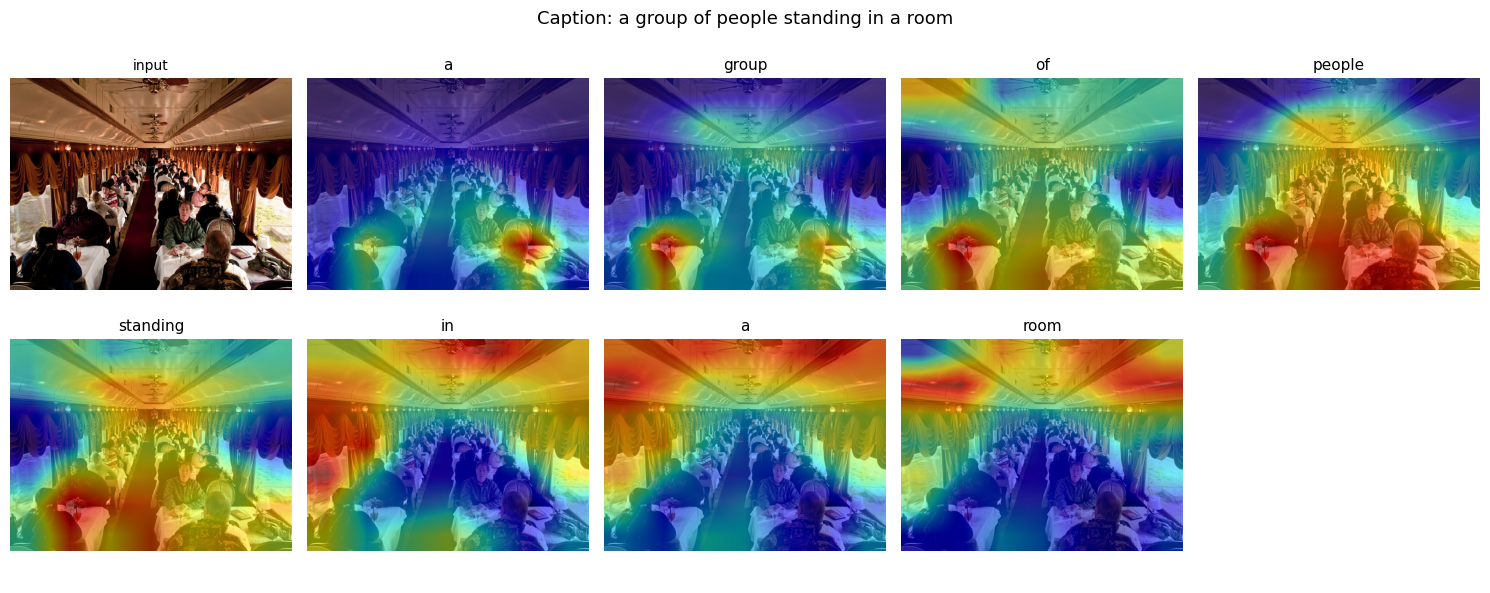

generated : a group of people standing in a room 

reference : a chicken sandwich in a wrapper near a cell phone


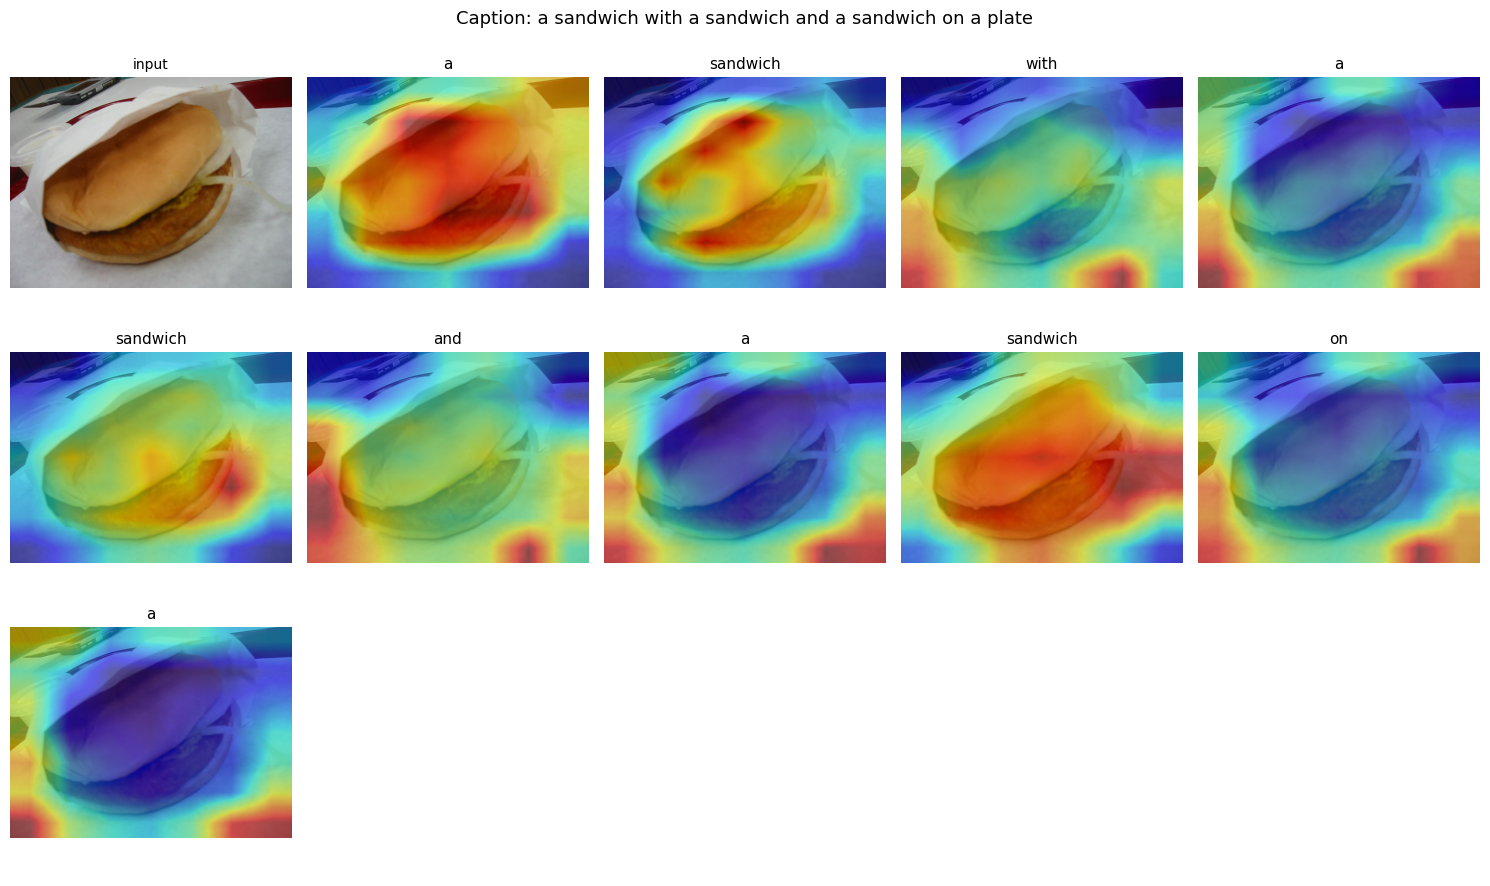

generated : a sandwich with a sandwich and a sandwich on a plate 



In [23]:
# A few COCO validation images, with their human captions for comparison
for it in random.sample(splits["val"], 3):
    print("reference :", " ".join(it["caps"][0]))
    cap, _, _ = caption_image(COCO_ROOT / it["path"], decoder, show=True)
    print("generated :", cap, "\n")